# Random Forest Classifier: Bagged-Ensemble Benchmark for Employee Resignation Prediction

**Member 2 supplementary model: Random Forest** (`sklearn.ensemble.RandomForestClassifier`)

This notebook adds a **bagging** baseline next to the boosted models (CatBoost, XGBoost, LightGBM). It follows the shared evaluation contract:

1. Only the 80,000-row **development** partition is read. The 20,000-row formal holdout is never parsed.
2. The five frozen `cv_fold` assignments from the split registry are used unchanged. No private splits are created.
3. One-hot encoding and candidate selection happen **inside each outer training fold** (fold-local preprocessing).
4. Out-of-fold (OOF) probabilities are produced by this notebook's own five-fold runner (Section 1.1) and re-validated against the frozen registry by the group's `load_saved_model_evidence` check.

**Why Random Forest?** A forest averages many decorrelated, deep trees, which lowers variance without the sequential bias-correction of boosting. If a boosted model's result were only an artefact of boosting hyper-parameters, a bagged ensemble would show it. It is also a standard non-linear benchmark that handles mixed numeric and one-hot features without scaling.

**Everything is in this notebook.** Data loading, metrics, the five-fold runner, the model adapter and the manual prediction tools are all defined here; no project `.py` file is used except the group's read-only `load_saved_model_evidence` check of the saved OOF files (the same check every model notebook uses).

**Execution switch:** `RUN_EXPERIMENT = False` reviews saved evidence in `results/models/random_forest/`, without fitting or writing. Section 12 (manual prediction) fits one final forest in memory for scoring new employees; it writes nothing. Set it to `True` to retrain (about 25 forest fits).

## 1. Setup and Execution Switch

Locate the project root through the feature-contract anchor, so paths are relative and the notebook runs on any machine. Display options are set once for readable tables. All paths use `pathlib.Path`.

In [1]:
from __future__ import annotations

import copy
import hashlib
import json
import sys
import tempfile
import time
from pathlib import Path
from types import SimpleNamespace

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import yaml
from IPython.display import display
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "configs" / "feature_contract.yaml").is_file())
sys.path.insert(0, str(ROOT))

# The only shared group code used: the read-only validator for saved OOF evidence
from src.evaluation.inputs import load_saved_model_evidence

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")

SEED = 42
MODEL_NAME = "Random Forest Classifier"
MODEL_ID = "random_forest"
OUT = ROOT / "results" / "models" / "random_forest"

RUN_EXPERIMENT = False  # True retrains and writes results/models/random_forest/. False = saved review only.
print(f"Project root: {ROOT}\nscikit-learn {sklearn.__version__} | RUN_EXPERIMENT={RUN_EXPERIMENT}")

Project root: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project
scikit-learn 1.9.0 | RUN_EXPERIMENT=False


### 1.1 In-Notebook Helpers (data loader, metrics, five-fold runner)

These functions replace the project's shared `.py` helpers, so the whole Random Forest workflow lives in this notebook:

- **`load_development_data`** checks the raw file and split registry against their frozen SHA-256 fingerprints. It then reads **only the 80,000 development rows**: holdout rows are skipped while the file is parsed, so their labels are never loaded.
- **`calculate_binary_metrics`** computes the project's standard metrics: AP, ROC-AUC, precision, recall, F1, balanced accuracy, accuracy, Brier score and the confusion counts.
- **`run_5fold_cv`** creates a **fresh adapter per fold**, fits it only on the four outer-training folds, predicts the held-out fold and checks every probability. It then assembles the OOF table and the fold and summary metrics.

They reproduce the group helpers' behaviour exactly, and the saved OOF results are identical when retrained.

In [2]:
# ------------------------------------------------------------
# IN-NOTEBOOK HELPERS: CONTRACT, DATA LOADER, METRICS AND 5-FOLD RUNNER
# ------------------------------------------------------------
# Frozen group contract: predictor lists, excluded columns and file fingerprints
CONTRACT = yaml.safe_load((ROOT / "configs" / "feature_contract.yaml").read_text(encoding="utf-8"))


# Predictor names in contract order
def numerical_feature_names():
    return [feature["name"] for feature in CONTRACT.get("numerical_features", [])]


def categorical_feature_names():
    return [feature["name"] for feature in CONTRACT.get("categorical_features", [])]


# Reject anything that is not a 1-D array of 0/1 labels
def validate_binary_targets(values, name="y_true"):
    values = np.asarray(values)
    if values.ndim != 1 or len(values) == 0 or values.dtype.kind not in "biuf" or not np.isfinite(values).all():
        raise ValueError(f"{name} must be a non-empty 1-D array of numeric binary labels.")
    if not set(np.unique(values)).issubset({0, 1}):
        raise ValueError(f"{name} must contain only binary labels 0 and 1.")


# Development rows only: verify fingerprints, then skip holdout rows while parsing
def load_development_data(root):
    for key in ("dataset", "split_registry"):
        path = root / CONTRACT[key]["path"]
        digest = hashlib.sha256(path.read_bytes().replace(b"\r\n", b"\n")).hexdigest()
        if digest != CONTRACT[key]["sha256"]:
            raise ValueError(f"Frozen {key} checksum mismatch.")
    split = pd.read_csv(root / CONTRACT["split_registry"]["path"])
    if split.Employee_ID.isna().any() or not split.Employee_ID.is_unique:
        raise ValueError("Frozen registry IDs must be present and unique.")
    development = split.loc[split.partition == "development"]
    if len(development) != CONTRACT["split_registry"]["development_rows"]:
        raise ValueError("Frozen development row count mismatch.")
    path = root / CONTRACT["dataset"]["path"]
    identifiers = pd.read_csv(path, usecols=["Employee_ID"])
    ids = set(development.Employee_ID)
    skip = [i + 1 for i, value in enumerate(identifiers.Employee_ID) if value not in ids]
    frame = pd.read_csv(path, skiprows=skip)
    if not frame.Employee_ID.is_unique or set(frame.Employee_ID) != ids:
        raise ValueError("Source development IDs do not match the frozen registry.")
    validate_binary_targets(frame.Resigned.to_numpy(), name="Resigned")
    frame["Resigned"] = frame.Resigned.astype(int)
    print(f"Rows before/after development isolation: {len(identifiers):,} -> {len(frame):,}; "
          f"Resigned prevalence={frame.Resigned.mean():.5f} (imbalanced; no resampling during saved review).")
    return frame, split


# Standard binary metrics (y_pred defaults to probability >= threshold)
def calculate_binary_metrics(y_true, y_probability, y_pred=None, threshold=0.5):
    y_true = np.asarray(y_true)
    validate_binary_targets(y_true)
    y_true = y_true.astype(int)
    y_probability = np.asarray(y_probability, dtype=float)
    if y_probability.ndim != 1 or not np.isfinite(y_probability).all() or (y_probability < 0).any() or (y_probability > 1).any():
        raise ValueError("Probabilities must be a 1-D array of finite values in [0, 1].")
    if len(y_true) != len(y_probability):
        raise ValueError("y_true and y_probability must have the same length.")
    y_pred = (y_probability >= threshold).astype(int) if y_pred is None else np.asarray(y_pred)
    validate_binary_targets(y_pred, name="y_pred")
    y_pred = y_pred.astype(int)
    if len(np.unique(y_true)) < 2:
        raise ValueError("Both target classes must be present to calculate ROC-AUC.")
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "average_precision": float(average_precision_score(y_true, y_probability)),
        "roc_auc": float(roc_auc_score(y_true, y_probability)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1": float(f1_score(y_true, y_pred, zero_division=0)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "brier_score": float(brier_score_loss(y_true, y_probability)),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "predicted_positive_count": int(y_pred.sum()),
        "predicted_positive_rate": float(y_pred.mean()),
    }


# Leakage-safe five-fold OOF runner: a fresh adapter per fold, outer validation never used for fitting
def run_5fold_cv(adapter_factory, data, split_registry, feature_cols, expected_model_name=None,
                 target_col="Resigned", id_col="Employee_ID", fold_col="cv_fold", expected_folds=(1, 2, 3, 4, 5)):
    feature_cols = list(feature_cols)
    # Predictors may not include IDs, the target, split columns or contract-excluded columns
    forbidden = {item["column"] for item in CONTRACT["excluded_features"]} | {target_col, id_col, fold_col, "partition"}
    if forbidden & set(feature_cols) or len(feature_cols) != len(set(feature_cols)):
        raise ValueError(f"Invalid predictor list: {sorted(forbidden & set(feature_cols))}")
    # Holdout rows must never be present
    holdout_ids = set(split_registry.loc[split_registry.partition == "holdout", id_col])
    if holdout_ids & set(data[id_col]):
        raise ValueError("Formal holdout records were passed to the CV runner.")
    # Development rows with their frozen fold numbers (row order kept)
    dev_registry = split_registry.loc[split_registry.partition == "development", [id_col, fold_col]].copy()
    dev_registry[fold_col] = dev_registry[fold_col].astype(int)
    dev_data = data.loc[data[id_col].isin(set(dev_registry[id_col]))].copy()
    dev_data = dev_data.drop(columns=[c for c in (fold_col, "partition") if c in dev_data.columns])
    dev_data = dev_data.merge(dev_registry, on=id_col, validate="one_to_one")
    if len(dev_data) != len(dev_registry) or not dev_data[id_col].is_unique:
        raise ValueError("Development rows do not match the frozen registry.")
    validate_binary_targets(dev_data[target_col].to_numpy(), name=target_col)
    if sorted(dev_data[fold_col].unique()) != sorted(expected_folds):
        raise ValueError("Observed folds do not match the expected folds.")

    fold_frames, fold_records, fold_metadata = [], [], []
    total_fit = total_predict = 0.0
    last_metadata = {}
    for fold in sorted(expected_folds):
        # Fresh adapter for every fold, so no state leaks between folds
        adapter = adapter_factory()
        if expected_model_name is not None and adapter.name != expected_model_name:
            raise ValueError(f"Adapter name mismatch on fold {fold}.")
        train_df = dev_data.loc[dev_data[fold_col] != fold]
        val_df = dev_data.loc[dev_data[fold_col] == fold]
        assert set(train_df[id_col]).isdisjoint(val_df[id_col]), f"Fold {fold}: training and validation overlap"

        # Fit on the four outer-training folds only, then predict the held-out fold
        t0 = time.perf_counter()
        adapter.fit(X=train_df[feature_cols], y=train_df[target_col])
        fit_seconds = time.perf_counter() - t0
        t0 = time.perf_counter()
        y_prob = np.asarray(adapter.predict_proba(X=val_df[feature_cols]), dtype=float)
        predict_seconds = time.perf_counter() - t0
        total_fit += fit_seconds
        total_predict += predict_seconds
        if y_prob.ndim != 1 or len(y_prob) != len(val_df) or not np.isfinite(y_prob).all() \
                or (y_prob < 0).any() or (y_prob > 1).any():
            raise ValueError(f"Fold {fold}: invalid probability output.")

        # Fold metrics at the 0.5 threshold, plus timing
        y_pred = (y_prob >= 0.5).astype(int)
        y_true = val_df[target_col].astype(int).to_numpy()
        record = calculate_binary_metrics(y_true, y_prob, y_pred, threshold=0.5)
        record.update(fold=fold, fit_time_seconds=float(fit_seconds), predict_time_seconds=float(predict_seconds),
                      pr_auc=record["average_precision"])
        fold_records.append(record)
        fold_frames.append(pd.DataFrame({"Employee_ID": val_df[id_col].to_numpy(), "cv_fold": fold, "y_true": y_true,
                                         "model_name": adapter.name, "y_probability": y_prob, "y_pred_0_5": y_pred}))
        last_metadata = copy.deepcopy(adapter.get_metadata())
        fold_metadata.append({"fold": fold, "adapter_metadata": last_metadata})

    # Assemble the OOF table: every development row exactly once
    predictions = pd.concat(fold_frames, ignore_index=True).sort_values("Employee_ID").reset_index(drop=True)
    assert predictions.Employee_ID.is_unique and len(predictions) == len(dev_data), "OOF table is incomplete"
    fold_metrics = pd.DataFrame(fold_records).sort_values("fold").reset_index(drop=True)
    pooled = calculate_binary_metrics(predictions.y_true, predictions.y_probability, predictions.y_pred_0_5)
    summary = {
        "model_name": adapter.name, "model_id": adapter.model_id,
        "total_development_records": len(predictions), "total_folds": len(expected_folds),
        "pooled_average_precision": pooled["average_precision"], "pooled_pr_auc": pooled["average_precision"],
        "pooled_roc_auc": pooled["roc_auc"], "pooled_f1": pooled["f1"], "pooled_brier_score": pooled["brier_score"],
        "cv_mean_average_precision": float(fold_metrics.average_precision.mean()),
        "cv_std_average_precision": float(fold_metrics.average_precision.std()),
        "cv_mean_pr_auc": float(fold_metrics.average_precision.mean()),
        "cv_std_pr_auc": float(fold_metrics.average_precision.std()),
        "cv_mean_roc_auc": float(fold_metrics.roc_auc.mean()), "cv_std_roc_auc": float(fold_metrics.roc_auc.std()),
        "cv_mean_f1": float(fold_metrics.f1.mean()), "cv_std_f1": float(fold_metrics.f1.std()),
        "total_fit_time_seconds": float(total_fit), "total_predict_time_seconds": float(total_predict),
    }
    return SimpleNamespace(predictions=predictions, fold_metrics=fold_metrics, summary_metrics=summary,
                           metadata={**last_metadata, "fold_metadata": fold_metadata})


print("In-notebook helpers ready: contract, development loader, metrics and five-fold runner.")


In-notebook helpers ready: contract, development loader, metrics and five-fold runner.


## 2. Data Ingestion, Holdout Quarantine and Class Balance

`load_development_data` verifies the SHA-256 of the raw file and the split registry, finds the holdout IDs from the registry and **skips those rows before predictors or labels are parsed**. Row counts are logged before and after isolation. The predictor lists come from the frozen feature contract, not from a hand-written list. `Employee_ID`, `Hire_Date` and `Resigned` are never predictors.

The target is imbalanced (about 10% `Resigned = 1`). Consequences for this notebook:

- **Average Precision (AP) is the primary metric**, read against the prevalence no-skill line, because accuracy is about 90% for a model that predicts nobody resigns.
- The registry's folds are stratified, so each outer fold keeps roughly the same prevalence.
- Class imbalance is handled with `class_weight` **as a tuned hyper-parameter** (unweighted, `balanced`, `balanced_subsample`). No resampling is used, and the choice is made on inner-validation data only.

In [3]:
data, split = load_development_data(ROOT)

NUMERIC = numerical_feature_names()
CATEGORICAL = categorical_feature_names()
FEATURES = NUMERIC + CATEGORICAL

assert not ({"Employee_ID", "Hire_Date", "Resigned"} & set(FEATURES))
holdout_ids = set(split.loc[split.partition == "holdout", "Employee_ID"])
assert holdout_ids.isdisjoint(data.Employee_ID), "Holdout rows leaked into development data"

fold_of = split.set_index("Employee_ID").cv_fold
data["cv_fold"] = data.Employee_ID.map(fold_of).astype(int)

prevalence = float(data.Resigned.mean())
print(f"Shape after development isolation: {data.shape} | predictors: {len(FEATURES)} "
      f"({len(NUMERIC)} numeric, {len(CATEGORICAL)} categorical)")
print(f"Holdout IDs in registry: {len(holdout_ids):,} (none present in data)")
print(f"Target distribution:\n{data.Resigned.value_counts().rename('count').to_frame().assign(share=lambda d: d['count'] / len(data))}")
print(f"Negative:positive ratio = {(1 - prevalence) / prevalence:.2f}:1 -> imbalanced; handled via class_weight candidates, no resampling.")
display(data.groupby("cv_fold").Resigned.agg(rows="size", positives="sum", prevalence="mean"))

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).
Shape after development isolation: (80000, 21) | predictors: 17 (13 numeric, 4 categorical)
Holdout IDs in registry: 20,000 (none present in data)
Target distribution:
          count   share
Resigned               
0         71992 0.89990
1          8008 0.10010
Negative:positive ratio = 8.99:1 -> imbalanced; handled via class_weight candidates, no resampling.


,rows,positives,prevalence
cv_fold,,,
1,16000,1601,0.10006
2,16000,1601,0.10006
3,16000,1602,0.10013
4,16000,1602,0.10013
5,16000,1602,0.10013


## 3. Candidate Registry (Hyper-parameter Rationale)

Four pre-declared candidates (`RF01` to `RF04`) cover the main Random Forest trade-offs. Every candidate uses `random_state=42` and `n_jobs=-1`.

| ID | Idea | Key settings |
|---|---|---|
| `RF01` | Unweighted baseline | 200 trees, depth 8, `min_samples_leaf=5`, `max_features="sqrt"` |
| `RF02` | Balanced bagging | adds `class_weight="balanced"`, 300 trees |
| `RF03` | Deep and balanced | 500 trees, depth 14, `min_samples_leaf=2`, `balanced_subsample` (higher variance, more overfitting risk) |
| `RF04` | Strongly regularised | depth 6, `min_samples_leaf=10`, `max_features="log2"`, `balanced` |

- **`max_depth` / `min_samples_leaf` / `min_samples_split`** limit how closely individual trees can memorise noise. This is the main regularisation lever in a forest.
- **`max_features`** (`sqrt` or `log2`) decorrelates trees. Fewer features per split means more diversity and a larger variance reduction when averaging.
- **`class_weight`** re-weights the minority class in the split criterion. It can raise recall at a 0.5 threshold, but it shifts probabilities away from the true base rate, which hurts Brier score and log loss. It is therefore selected on inner data and not assumed to help.

In [4]:
CANDIDATES = {
    "RF01": dict(n_estimators=200, max_depth=8,  min_samples_split=10, min_samples_leaf=5,  max_features="sqrt", class_weight=None),
    "RF02": dict(n_estimators=300, max_depth=8,  min_samples_split=10, min_samples_leaf=5,  max_features="sqrt", class_weight="balanced"),
    "RF03": dict(n_estimators=500, max_depth=14, min_samples_split=5,  min_samples_leaf=2,  max_features="sqrt", class_weight="balanced_subsample"),
    "RF04": dict(n_estimators=300, max_depth=6,  min_samples_split=20, min_samples_leaf=10, max_features="log2", class_weight="balanced"),
}
display(pd.DataFrame(CANDIDATES).T.rename_axis("candidate_id"))

,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
candidate_id,,,,,,
RF01,200,8,10,5,sqrt,None
RF02,300,8,10,5,sqrt,balanced
RF03,500,14,5,2,sqrt,balanced_subsample
RF04,300,6,20,10,log2,balanced


## 4. Leakage-Safe Model Adapter

`RandomForestAdapter` follows the group's model-adapter interface (`fit`, `predict_proba`, `save`, `load`, `get_metadata`), defined here in the notebook. Design decisions:

- **Fold-local preprocessing.** A `ColumnTransformer` one-hot encodes the four nominal predictors with `handle_unknown="ignore"` and passes numeric predictors through. Trees are invariant to monotone scaling, so no scaler is used. The encoder is fitted only on the rows given to `fit`.
- **Nested candidate selection.** Inside the outer-training rows, a stratified 15% inner validation split compares all candidates by AP (ties broken by ascending candidate ID). The winner is **refitted on all outer-training rows**. The outer validation fold is never seen during selection.
- **Protocol output.** `predict_proba` returns a **1-D array of positive-class probabilities** `P(Resigned=1)` in `[0, 1]`, not scikit-learn's `(N, 2)` matrix.
- **Overfitting evidence.** The adapter records the refit model's in-sample (training) AP in its metadata, so the train-versus-OOF gap can be reported.

In [5]:
class RandomForestAdapter:
    # Random Forest with fold-local one-hot encoding and inner-split candidate selection.

    name = MODEL_NAME
    model_id = MODEL_ID

    def __init__(self, candidates=None, numeric=None, categorical=None,
                 inner_fraction=0.15, random_state=SEED, n_jobs=-1):
        self.candidates = dict(candidates or CANDIDATES)
        self.numeric = list(numeric or NUMERIC)
        self.categorical = list(categorical or CATEGORICAL)
        self.inner_fraction = inner_fraction
        self.random_state = random_state
        self.n_jobs = n_jobs
        self._pipeline = None
        self._selected_id = None
        self._inner_results = []
        self._train_ap = None
        self._fit_seconds = None
        self._n_train = None

    def _build(self, params):
        encoder = ColumnTransformer(
            [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), self.categorical),
             ("num", "passthrough", self.numeric)],
            verbose_feature_names_out=False,
        )
        forest = RandomForestClassifier(random_state=self.random_state, n_jobs=self.n_jobs, **params)
        return Pipeline([("prep", encoder), ("forest", forest)])

    def fit(self, X, y):
        t0 = time.perf_counter()
        X = X[self.categorical + self.numeric].reset_index(drop=True)
        y = np.asarray(y).astype(int)
        idx = np.arange(len(y))
        fit_idx, val_idx = train_test_split(
            idx, test_size=self.inner_fraction, stratify=y, random_state=self.random_state)
        self._inner_results = []
        for cid in sorted(self.candidates):
            pipe = self._build(self.candidates[cid]).fit(X.iloc[fit_idx], y[fit_idx])
            p = pipe.predict_proba(X.iloc[val_idx])[:, 1]
            self._inner_results.append({
                "candidate_id": cid,
                "inner_average_precision": float(average_precision_score(y[val_idx], p)),
                "inner_fit_rows": int(len(fit_idx)), "inner_val_rows": int(len(val_idx)),
            })
        best = max(self._inner_results, key=lambda r: r["inner_average_precision"])  # first max in sorted-ID order
        self._selected_id = best["candidate_id"]
        # Refit the selected candidate on every outer-training row.
        self._pipeline = self._build(self.candidates[self._selected_id]).fit(X, y)
        self._train_ap = float(average_precision_score(y, self._pipeline.predict_proba(X)[:, 1]))
        self._n_train = int(len(y))
        self._fit_seconds = time.perf_counter() - t0
        return self

    def predict_proba(self, X):
        if self._pipeline is None:
            raise RuntimeError("RandomForestAdapter must be fitted before predict_proba.")
        proba = self._pipeline.predict_proba(X[self.categorical + self.numeric])
        positive = list(self._pipeline.classes_).index(1)
        return np.clip(np.asarray(proba[:, positive], dtype=float), 0.0, 1.0)  # shape (N,)

    def get_feature_importances(self):
        # Impurity-based (mean decrease in impurity) importances per one-hot expanded feature.
        if self._pipeline is None:
            raise RuntimeError("RandomForestAdapter must be fitted first.")
        names = self._pipeline.named_steps["prep"].get_feature_names_out()
        values = self._pipeline.named_steps["forest"].feature_importances_
        return (pd.DataFrame({"feature": names, "importance": values})
                .sort_values("importance", ascending=False).reset_index(drop=True))

    def get_metadata(self):
        meta = {"name": self.name, "model_id": self.model_id, "fitted": self._pipeline is not None}
        if self._pipeline is not None:
            meta.update({
                "selected_candidate": self._selected_id,
                "selected_params": self.candidates[self._selected_id],
                "inner_results": self._inner_results,
                "train_average_precision": self._train_ap,
                "n_train_rows": self._n_train,
                "fit_seconds": self._fit_seconds,
                "feature_importances": self.get_feature_importances().set_index("feature").importance.to_dict(),
            })
        return meta

    def save(self, directory):
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=True)
        joblib.dump(self._pipeline, directory / "model.joblib")
        meta = {**self.get_metadata(), "candidates": self.candidates,
                "numeric": self.numeric, "categorical": self.categorical}
        (directory / "metadata.json").write_text(json.dumps(meta, indent=2, default=float), encoding="utf-8")
        return {"directory": str(directory), "files": ["model.joblib", "metadata.json"]}

    @classmethod
    def load(cls, directory):
        directory = Path(directory)
        meta = json.loads((directory / "metadata.json").read_text(encoding="utf-8"))
        adapter = cls(candidates=meta["candidates"], numeric=meta["numeric"], categorical=meta["categorical"])
        adapter._pipeline = joblib.load(directory / "model.joblib")
        adapter._selected_id = meta.get("selected_candidate")
        adapter._inner_results = meta.get("inner_results", [])
        adapter._train_ap = meta.get("train_average_precision")
        adapter._n_train = meta.get("n_train_rows")
        return adapter

### 4.1 Adapter Contract Checks (small slice, no outer-fold data involved)

Before running the real evaluation, confirm on a 3,000-row slice that the adapter satisfies the protocol: unfitted metadata, 1-D bounded probabilities, correct importance names and an exact `save`/`load` round-trip. A tiny candidate pool keeps this fast. This slice is only a software check and its scores are not reported anywhere.

In [6]:
tiny = {"T1": dict(n_estimators=20, max_depth=4, min_samples_leaf=5, max_features="sqrt", class_weight=None),
        "T2": dict(n_estimators=20, max_depth=4, min_samples_leaf=5, max_features="sqrt", class_weight="balanced")}
probe = data.iloc[:3000]
adapter = RandomForestAdapter(candidates=tiny)

assert all(callable(getattr(adapter, m, None)) for m in ("fit", "predict_proba", "save", "load", "get_metadata"))
assert adapter.get_metadata() == {"name": MODEL_NAME, "model_id": MODEL_ID, "fitted": False}

adapter.fit(probe[FEATURES], probe.Resigned)
proba = adapter.predict_proba(probe[FEATURES])
assert proba.ndim == 1 and proba.shape == (len(probe),) and proba.min() >= 0 and proba.max() <= 1

importances = adapter.get_feature_importances()
assert np.isclose(importances.importance.sum(), 1.0)
assert any(name.startswith("Department_") for name in importances.feature)  # one-hot expanded names

with tempfile.TemporaryDirectory() as tmp:
    info = adapter.save(Path(tmp))
    restored = RandomForestAdapter.load(Path(tmp))
    assert np.allclose(restored.predict_proba(probe[FEATURES]), proba)

print("Adapter contract OK: protocol, 1-D probabilities in [0, 1], importance names and save/load round-trip.")
display(importances.head(5))

Adapter contract OK: protocol, 1-D probabilities in [0, 1], importance names and save/load round-trip.


,feature,importance
0,Monthly_Salary,0.14178
1,Overtime_Hours,0.10808
2,Training_Hours,0.10571
3,Employee_Satisfaction_Score,0.08392
4,Projects_Handled,0.07684


## 5. Five-Fold Out-of-Fold Evaluation

The in-notebook `run_5fold_cv` (Section 1.1) creates a **fresh adapter per fold**, fits it strictly on the four outer-training folds, predicts the held-out fold and validates every probability. It then assembles the OOF table. The saved table is checked against the frozen registry (IDs, folds, labels) by the group's `load_saved_model_evidence`. Each fold runs the nested candidate selection from section 4, so the 25 forest fits are 5 folds x (4 inner candidates + 1 refit).

With `RUN_EXPERIMENT = False` the saved artefacts are loaded and re-validated instead. Pooled AP, ROC-AUC and Brier are recomputed from the OOF probabilities and must match the saved summary.

In [7]:
if RUN_EXPERIMENT:
    OUT.mkdir(parents=True, exist_ok=True)
    result = run_5fold_cv(
        adapter_factory=RandomForestAdapter,
        data=data[["Employee_ID", "Resigned", *FEATURES]],
        split_registry=split,
        feature_cols=FEATURES,
        expected_model_name=MODEL_NAME,
    )
    pooled = calculate_binary_metrics(result.predictions.y_true, result.predictions.y_probability,
                                      result.predictions.y_pred_0_5)
    summary_out = {
        **result.summary_metrics,
        **{f"pooled_{k}": v for k, v in pooled.items() if f"pooled_{k}" not in result.summary_metrics},
        "development_prevalence": prevalence,
        "ap_lift_over_prevalence": result.summary_metrics["pooled_average_precision"] / prevalence,
        "formal_holdout_accessed": False,
        "random_state": SEED,
        "candidates": CANDIDATES,
    }
    meta = result.metadata["fold_metadata"]
    selection = pd.DataFrame([
        {"fold": m["fold"], "candidate_id": r["candidate_id"],
         "inner_average_precision": r["inner_average_precision"],
         "selected": r["candidate_id"] == m["adapter_metadata"]["selected_candidate"]}
        for m in meta for r in m["adapter_metadata"]["inner_results"]])
    train_gap = pd.DataFrame([
        {"fold": m["fold"], "selected_candidate": m["adapter_metadata"]["selected_candidate"],
         "train_average_precision": m["adapter_metadata"]["train_average_precision"]} for m in meta])
    importance = (pd.DataFrame([m["adapter_metadata"]["feature_importances"] for m in meta])
                  .rename_axis("fold").T.rename_axis("feature"))
    importance = importance.assign(mean_importance=importance.mean(axis=1), std_importance=importance.std(axis=1)
                                   ).sort_values("mean_importance", ascending=False)

    result.predictions.to_csv(OUT / "oof_predictions.csv", index=False)
    result.fold_metrics.to_csv(OUT / "fold_metrics.csv", index=False)
    selection.to_csv(OUT / "candidate_selection.csv", index=False)
    train_gap.to_csv(OUT / "train_gap.csv", index=False)
    importance.reset_index().to_csv(OUT / "feature_importance.csv", index=False)
    (OUT / "summary_metrics.json").write_text(json.dumps(summary_out, indent=2, default=float), encoding="utf-8")
    print(f"Saved Random Forest evidence to {OUT.relative_to(ROOT)}")

predictions, folds, summary = load_saved_model_evidence(ROOT, MODEL_NAME, OUT)
selection = pd.read_csv(OUT / "candidate_selection.csv")
train_gap = pd.read_csv(OUT / "train_gap.csv")
importance = pd.read_csv(OUT / "feature_importance.csv")
print(f"OOF rows: {len(predictions):,} | folds: {sorted(predictions.cv_fold.unique())} | "
      f"unique IDs: {predictions.Employee_ID.is_unique} | OOF validation passed; holdout excluded.")

Rows before/after development isolation: 100,000 -> 80,000; Resigned prevalence=0.10010 (imbalanced; no resampling during saved review).


OOF rows: 80,000 | folds: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)] | unique IDs: True | OOF validation passed; holdout excluded.


## 6. Metrics Against No-Skill References

Reference points on this imbalanced target:

- **AP:** a no-skill ranking scores the prevalence (about 0.100). Use AP lift over prevalence.
- **ROC-AUC:** no skill is 0.5.
- **Brier score and log loss:** compare with a constant prediction equal to the prevalence. Brier is about `p(1-p)` = 0.090. A model with *worse* probability error than that constant is not adding calibrated information.
- **F1 / recall at 0.5:** depend on the fixed 0.5 threshold. Unweighted forests often predict no positives at 10% prevalence, which gives F1 = 0 even though the ranking is evaluated independently.

Thresholds are fixed at 0.5. No threshold is tuned on outer labels.

In [8]:
y, p = predictions.y_true.to_numpy(), predictions.y_probability.to_numpy()
const = np.full_like(p, prevalence)
ref = calculate_binary_metrics(y, const, np.zeros_like(y))
pooled = calculate_binary_metrics(y, p, predictions.y_pred_0_5)
ref["log_loss"] = float(log_loss(y, const))
pooled["log_loss"] = float(log_loss(y, p))

metrics_table = pd.DataFrame({
    "Random Forest (pooled OOF)": {k: pooled[k] for k in ["average_precision", "roc_auc", "brier_score", "log_loss", "f1", "recall", "precision"] if k in pooled},
    "Prevalence constant": {k: ref.get(k, np.nan) for k in ["average_precision", "roc_auc", "brier_score", "log_loss", "f1", "recall", "precision"]},
})
display(metrics_table)
print(f"AP lift over prevalence: {pooled['average_precision'] / prevalence:.4f}x | "
      f"predicted-positive rate at 0.5: {(predictions.y_pred_0_5 == 1).mean():.4%}")
display(folds[["fold", "average_precision", "roc_auc", "f1", "brier_score", "fit_time_seconds", "predict_time_seconds"]])
print(f"Fold AP mean +/- SD: {folds.average_precision.mean():.5f} +/- {folds.average_precision.std():.5f} | "
      f"Fold ROC-AUC mean +/- SD: {folds.roc_auc.mean():.5f} +/- {folds.roc_auc.std():.5f}")

,Random Forest (pooled OOF),Prevalence constant
average_precision,0.10079,0.10010
roc_auc,0.50118,0.50000
brier_score,0.15328,0.09008
log_loss,0.47883,0.32530
f1,0.09372,0.00000
recall,0.08741,0.00000
precision,0.10101,0.00000


AP lift over prevalence: 1.0068x | predicted-positive rate at 0.5: 8.6625%


,fold,average_precision,roc_auc,f1,brier_score,fit_time_seconds,predict_time_seconds
0,1,0.09941,0.50004,0.00000,0.09010,9.09976,0.07830
1,2,0.10164,0.49858,0.16369,0.24721,9.45576,0.10962
2,3,0.10045,0.49797,0.00000,0.09013,9.40075,0.08939
3,4,0.10747,0.51229,0.00373,0.17074,12.30429,0.20625
4,5,0.10123,0.50549,0.00000,0.16820,12.68311,0.20546


Fold AP mean +/- SD: 0.10204 +/- 0.00315 | Fold ROC-AUC mean +/- SD: 0.50287 +/- 0.00604


## 7. Nested Candidate Selection Evidence

Each outer fold evaluated all four candidates on its own 15% inner validation split (about 9,600 rows, about 960 positives). **Inner AP is a noisy estimate**, since a standard error of roughly 0.01 on about 960 positives is larger than typical gaps between candidates. The table therefore shows the selection, not proof that the winner is truly better.

In [9]:
pivot = selection.pivot(index="fold", columns="candidate_id", values="inner_average_precision")
pivot["selected"] = selection.loc[selection.selected].set_index("fold").candidate_id
display(pivot)
print("Selection frequency:", selection.loc[selection.selected].candidate_id.value_counts().to_dict())
print(f"Mean inner AP by candidate:\n{selection.groupby('candidate_id').inner_average_precision.mean().to_frame('mean_inner_AP')}")

candidate_id,RF01,RF02,RF03,RF04,selected
fold,,,,,
1,0.10391,0.10094,0.10013,0.10090,RF01
2,0.09824,0.10083,0.10007,0.10144,RF04
3,0.10478,0.10389,0.10172,0.09899,RF01
4,0.10176,0.10044,0.10226,0.09826,RF03
5,0.10010,0.10178,0.10611,0.10132,RF03


Selection frequency: {'RF01': 2, 'RF03': 2, 'RF04': 1}
Mean inner AP by candidate:
              mean_inner_AP
candidate_id               
RF01                0.10176
RF02                0.10157
RF03                0.10206
RF04                0.10018


## 8. Overfitting Check: Training AP versus Out-of-Fold AP

A forest with deep trees can fit its own training rows almost perfectly, because each row is in-bag for about 63% of trees. That makes **in-sample AP a poor measure of generalisation**. Only the gap to OOF AP matters. A large gap with no OOF lift over prevalence indicates memorised noise rather than learned signal. The OOB-style optimism of the training score is expected and is not itself a defect.

In [10]:
gap = train_gap.merge(folds[["fold", "average_precision"]].rename(columns={"average_precision": "oof_average_precision"}), on="fold")
gap["train_minus_oof_ap"] = gap.train_average_precision - gap.oof_average_precision
display(gap)
print(f"Mean in-sample AP {gap.train_average_precision.mean():.4f} vs mean OOF AP {gap.oof_average_precision.mean():.4f} "
      f"(prevalence {prevalence:.4f}); mean gap {gap.train_minus_oof_ap.mean():.4f}")

,fold,selected_candidate,train_average_precision,oof_average_precision,train_minus_oof_ap
0,1,RF01,0.51649,0.09941,0.41708
1,2,RF04,0.25060,0.10164,0.14896
2,3,RF01,0.53902,0.10045,0.43857
3,4,RF03,0.99983,0.10747,0.89236
4,5,RF03,0.99990,0.10123,0.89867


Mean in-sample AP 0.6612 vs mean OOF AP 0.1020 (prevalence 0.1001); mean gap 0.5591


## 9. Diagnostic Figures

Figures use only OOF probabilities (never in-sample scores). With `RUN_EXPERIMENT = True` they are also written to `results/models/random_forest/`.

1. **Precision-recall curve** against the prevalence line (primary imbalance view).
2. **ROC curve** against the diagonal.
3. **Probability distribution by class.** If the two class distributions overlap almost completely, there is no usable ranking signal.
4. **Reliability (calibration) curve** with quantile bins.
5. **Confusion matrices** at the fixed 0.5 threshold and at an *operational* top-10% threshold (flag the highest-risk 10%, matching prevalence). The second is descriptive and is not tuned on labels.
6. **Feature importance** (mean over folds, with fold SD).

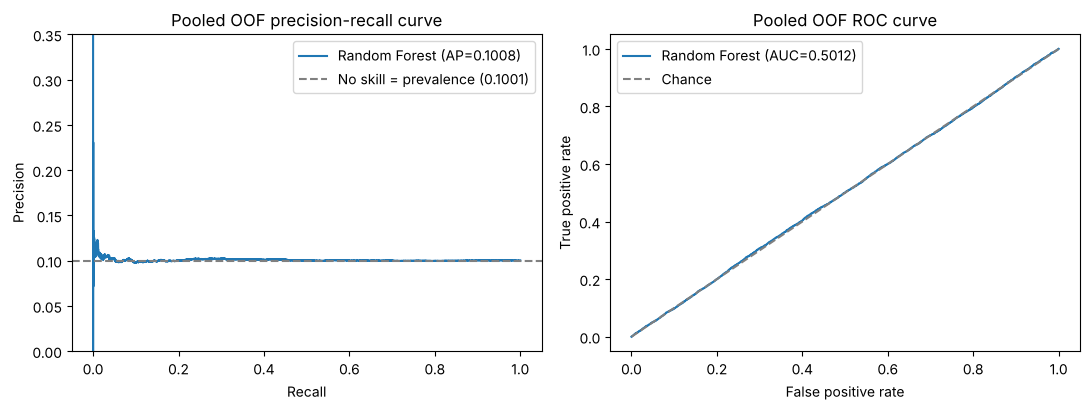

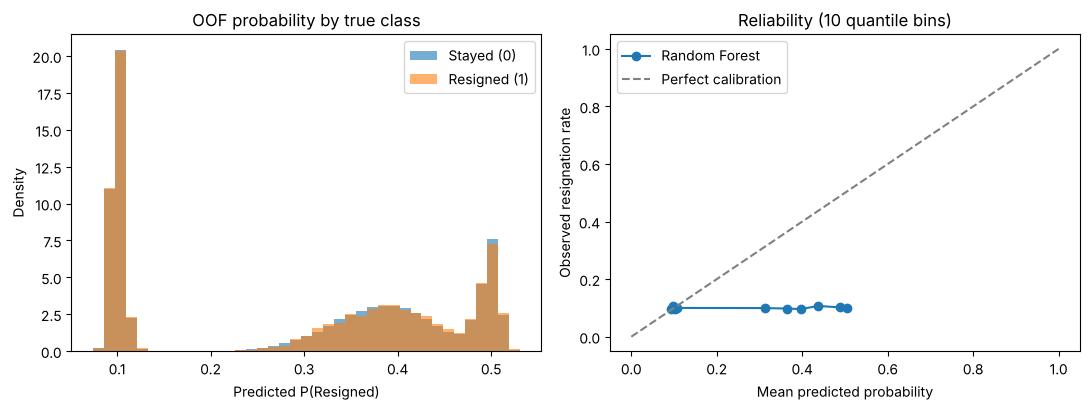

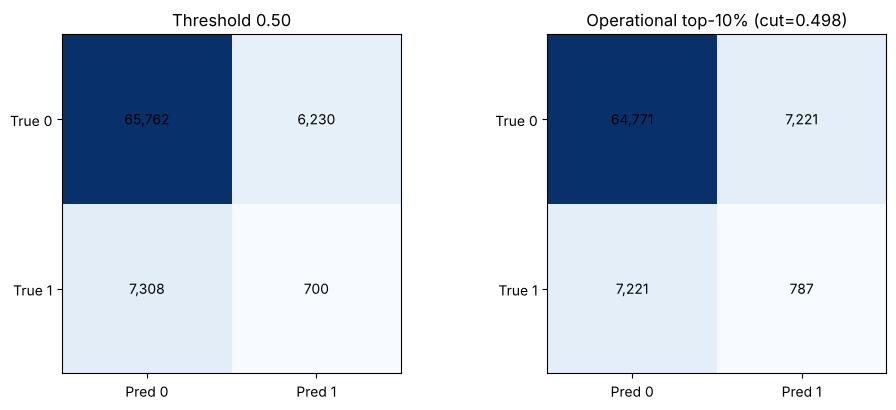

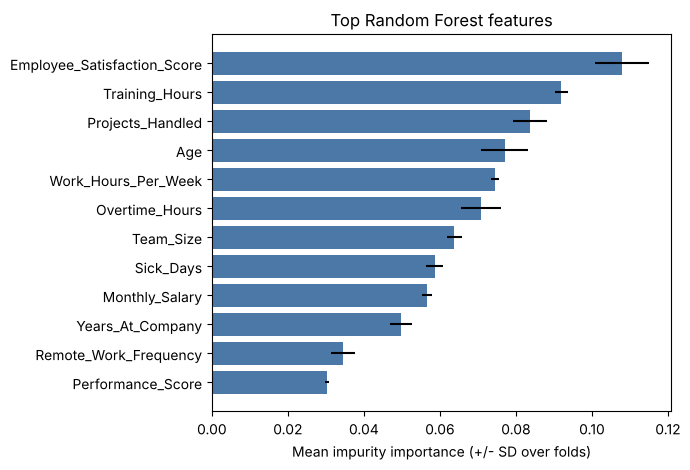

Operational top-10% precision 0.0983 -> lift 0.982x over random allocation.


In [11]:
def finish(fig, filename):
    fig.tight_layout()
    if RUN_EXPERIMENT:
        fig.savefig(OUT / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
prec, rec, _ = precision_recall_curve(y, p)
ax[0].plot(rec, prec, label=f"Random Forest (AP={pooled['average_precision']:.4f})")
ax[0].axhline(prevalence, ls="--", c="grey", label=f"No skill = prevalence ({prevalence:.4f})")
ax[0].set(xlabel="Recall", ylabel="Precision", title="Pooled OOF precision-recall curve", ylim=(0, 0.35)); ax[0].legend()
fpr, tpr, _ = roc_curve(y, p)
ax[1].plot(fpr, tpr, label=f"Random Forest (AUC={pooled['roc_auc']:.4f})"); ax[1].plot([0, 1], [0, 1], "--", c="grey", label="Chance")
ax[1].set(xlabel="False positive rate", ylabel="True positive rate", title="Pooled OOF ROC curve"); ax[1].legend()
finish(fig, "figure_01_random_forest_pr_roc.png")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
bins = np.linspace(p.min(), p.max(), 40)
ax[0].hist(p[y == 0], bins=bins, alpha=.6, density=True, label="Stayed (0)")
ax[0].hist(p[y == 1], bins=bins, alpha=.6, density=True, label="Resigned (1)")
ax[0].set(xlabel="Predicted P(Resigned)", ylabel="Density", title="OOF probability by true class"); ax[0].legend()
frac_pos, mean_pred = calibration_curve(y, p, n_bins=10, strategy="quantile")
ax[1].plot(mean_pred, frac_pos, "o-", label="Random Forest"); ax[1].plot([0, 1], [0, 1], "--", c="grey", label="Perfect calibration")
ax[1].set(xlabel="Mean predicted probability", ylabel="Observed resignation rate", title="Reliability (10 quantile bins)"); ax[1].legend()
finish(fig, "figure_02_random_forest_probability_calibration.png")

top_cut = np.quantile(p, 1 - prevalence)
op_pred = (p >= top_cut).astype(int)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
for a, pred, title in [(ax[0], predictions.y_pred_0_5.to_numpy(), "Threshold 0.50"),
                       (ax[1], op_pred, f"Operational top-{prevalence:.0%} (cut={top_cut:.3f})")]:
    cm = confusion_matrix(y, pred, labels=[0, 1])
    a.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        a.text(j, i, f"{v:,}", ha="center", va="center", color="black")
    a.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"], title=title)
finish(fig, "figure_03_random_forest_confusion_matrices.png")

top = importance.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(top.feature, top.mean_importance, xerr=top.std_importance, color="#4C78A8")
ax.set(xlabel="Mean impurity importance (+/- SD over folds)", title="Top Random Forest features")
finish(fig, "figure_04_random_forest_feature_importance.png")

op_precision = y[op_pred == 1].mean()
print(f"Operational top-10% precision {op_precision:.4f} -> lift {op_precision / prevalence:.3f}x over random allocation.")

### Reading the feature importances

Impurity importance is **biased toward high-cardinality, continuous predictors** such as `Monthly_Salary`, because they offer many more split points than binary one-hot indicators. A continuous column can rank first purely because it gives trees more chances to fit noise. Importance describes what the trees used, **not** what causally drives resignation. When OOF AP is near prevalence, treat this ranking as a descriptive artefact, not as findings about employee behaviour. A permutation importance on the held-out fold would be the appropriate follow-up before drawing any conclusion.

## 10. Benchmark Against the Boosted Models

The saved strict-nested summaries of the other models are compared on the same 80,000 development OOF rows and the same five folds. Where a file is missing it is skipped. A metric that a model's summary does not record (for example CatBoost's F1@0.5 and runtimes) is shown as NaN. Runtimes are wall-clock totals from each model's own run and are hardware- and protocol-dependent (CatBoost's total includes a larger candidate search), so they are context, not a like-for-like efficiency ranking.

In [12]:
sources = {"CatBoost": "catboost", "XGBoost": "xgboost", "LightGBM": "lightgbm", "Random Forest": "random_forest"}
rows = []
for label, folder in sources.items():
    path = ROOT / "results" / "models" / folder / "summary_metrics.json"
    if not path.is_file():
        continue
    s = json.loads(path.read_text(encoding="utf-8"))
    rows.append({"model": label,
                 "AP": s.get("pooled_average_precision"), "ROC_AUC": s.get("pooled_roc_auc"),
                 "Brier": s.get("pooled_brier_score"), "F1@0.5": s.get("pooled_f1"),
                 "fit_s_total": s.get("total_fit_time_seconds"), "predict_s_total": s.get("total_predict_time_seconds")})
comparison = pd.DataFrame(rows).set_index("model")
comparison["AP_lift"] = comparison.AP / prevalence
display(comparison)
print(f"No-skill references: AP={prevalence:.4f}, ROC-AUC=0.5000, constant-prevalence Brier={ref['brier_score']:.4f}")

,AP,ROC_AUC,Brier,F1@0.5,fit_s_total,predict_s_total,AP_lift
model,,,,,,,
CatBoost,0.09986,0.49961,0.09010,NaN,NaN,NaN,0.99761
XGBoost,0.10118,0.50247,0.17533,0.13452,53.12671,0.27511,1.01080
LightGBM,0.10255,0.50658,0.09069,0.00000,11.59965,0.78418,1.02451
Random Forest,0.10079,0.50118,0.15328,0.09372,52.94369,0.68901,1.00685


No-skill references: AP=0.1001, ROC-AUC=0.5000, constant-prevalence Brier=0.0901


## 11. Evidence-Based Conclusion

The cell below reports the outcome **from the recomputed numbers**, so the text cannot drift from the data.

**Interpretation guide**

- AP lift close to 1.0 and ROC-AUC close to 0.5 mean the forest has no useful discriminative skill on these predictors, regardless of tuning.
- A Brier score or log loss *above* the constant-prevalence reference means the probabilities are less reliable than predicting the base rate. This is typical when `class_weight` is applied.
- A large train-minus-OOF AP gap alongside no OOF lift is overfitting, not signal.
- Agreement between independent model families (bagged and boosted) pointing to the same near-chance result is evidence about the **data**, not about any single algorithm.

In [13]:
lift = pooled["average_precision"] / prevalence
print(f"Random Forest OOF AP={pooled['average_precision']:.5f} (prevalence {prevalence:.5f}, lift {lift:.4f}x); "
      f"ROC-AUC={pooled['roc_auc']:.5f} (chance 0.5).")
print(f"Brier={pooled['brier_score']:.5f} vs constant-prevalence {ref['brier_score']:.5f}; "
      f"log loss={pooled['log_loss']:.5f} vs {ref['log_loss']:.5f}.")
print(f"Mean in-sample AP {gap.train_average_precision.mean():.4f} vs OOF AP {gap.oof_average_precision.mean():.4f}.")
if lift < 1.05 and abs(pooled["roc_auc"] - 0.5) < 0.02:
    print("Verdict: no practically useful resignation ranking; practical lift over random is negligible.")
else:
    print("Verdict: some ranking signal above chance; confirm with uncertainty estimates before use.")
if pooled["brier_score"] > ref["brier_score"]:
    print("Calibration: probabilities are worse than the base rate (expected with class weighting); do not use them as risk estimates without recalibration.")
assert summary["formal_holdout_accessed"] is False
print("Formal holdout was never accessed; all numbers above are development OOF.")

Random Forest OOF AP=0.10079 (prevalence 0.10010, lift 1.0068x); ROC-AUC=0.50118 (chance 0.5).
Brier=0.15328 vs constant-prevalence 0.09008; log loss=0.47883 vs 0.32530.
Mean in-sample AP 0.6612 vs OOF AP 0.1020.
Verdict: no practically useful resignation ranking; practical lift over random is negligible.
Calibration: probabilities are worse than the base rate (expected with class weighting); do not use them as risk estimates without recalibration.
Formal holdout was never accessed; all numbers above are development OOF.


### Limitations and next steps

- Selection used one 15% inner split per fold. Repeated inner CV would give a more stable choice, but the candidate gaps are within noise anyway.
- Only AP was used for selection. A log-loss criterion would favour the unweighted candidates and better calibration.
- Impurity importances are biased (see section 9). Use permutation importance or SHAP before explaining the model.
- Fold-to-fold variance of AP is larger than most between-model differences, so ranking the models by pooled AP alone overstates differences. A paired bootstrap on shared OOF rows is the appropriate test (see the group comparison notebooks).
- This notebook does not change the six headline models or touch the formal holdout.

## 12. Manual Employee Input and Prediction

Three ways to score one employee with a final Random Forest:

1. **Terminal input (12.1):** the notebook asks for each field one at a time with `input()`, like a command-line program. Each answer is checked immediately and asked again if it is invalid. Pressing Enter accepts the shown default.
2. **Interactive form (12.2):** drop-downs and bounded number boxes, then a **Predict** button.
3. **Dictionary input (12.3):** edit the values in a Python dictionary and run the cell.

**Final model.** The saved nested selection chose a different candidate in different folds. The final forest uses the candidate chosen in the most outer folds, with ties going to the higher mean inner AP. It is refitted on all 80,000 development rows, in memory only, in about 20–30 seconds. The formal holdout is never read.

**Reading the score.** A candidate with `class_weight` produces inflated scores, so its score is a **ranking score, not a calibrated probability**. The HR flag therefore uses a **top-10% budget threshold** taken from that candidate's own out-of-fold scores, not the 10% base rate.

**After reopening the notebook you do not need Run All.** Run the **PREDICTION SETUP** cell below, then whichever input cell you want.

In [14]:
# ------------------------------------------------------------
# PREDICTION SETUP: FINAL FOREST, INPUT RULES AND PREDICTION FUNCTION
# ------------------------------------------------------------
# This cell works on its own: after reopening the notebook you can run it directly,
# with no need for Run All. It fits one final forest in memory (about 20-30 seconds)
# and writes nothing to disk. Running it again reuses the forest already in memory.
import json
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

# Project root (the same anchor as Section 1) and the frozen feature contract
if "ROOT" not in globals():
    _here = Path.cwd().resolve()
    ROOT = next(p for p in (_here, *_here.parents) if (p / "configs" / "feature_contract.yaml").is_file())
_contract = yaml.safe_load((ROOT / "configs" / "feature_contract.yaml").read_text(encoding="utf-8"))
RF_OUT = ROOT / "results" / "models" / "random_forest"
PRED_CATEGORICAL = [f["name"] for f in _contract["categorical_features"]]
PRED_NUMERIC = [f["name"] for f in _contract["numerical_features"]]

# Development rows only; reuse the Section 2 table if it is in memory. Otherwise read the raw
# file while skipping every holdout row, so holdout labels are never loaded.
if "data" not in globals():
    _split = pd.read_csv(ROOT / _contract["split_registry"]["path"])
    _dev_ids = set(_split.loc[_split.partition == "development", "Employee_ID"])
    _raw = ROOT / _contract["dataset"]["path"]
    _ids = pd.read_csv(_raw, usecols=["Employee_ID"]).Employee_ID
    data = pd.read_csv(_raw, skiprows=[i + 1 for i, v in enumerate(_ids) if v not in _dev_ids])
    assert set(data.Employee_ID) == _dev_ids, "Development rows do not match the frozen registry."
    data["Resigned"] = data["Resigned"].astype(int)
dev = data[["Resigned", *PRED_CATEGORICAL, *PRED_NUMERIC]]

# Choose the final candidate from the saved nested-selection evidence:
# the candidate selected in the most outer folds; ties go to the higher mean inner AP
saved_summary = json.loads((RF_OUT / "summary_metrics.json").read_text(encoding="utf-8"))
saved_selection = pd.read_csv(RF_OUT / "candidate_selection.csv")
votes = saved_selection[saved_selection.selected].candidate_id.value_counts()
mean_inner_ap = saved_selection.groupby("candidate_id").inner_average_precision.mean()
FINAL_CANDIDATE = max(votes.index, key=lambda cid: (votes[cid], mean_inner_ap[cid]))
FINAL_PARAMS = saved_summary["candidates"][FINAL_CANDIDATE]

# Fit the final forest on all development rows (the same pipeline as the CV adapter in Section 4)
if globals().get("rf_final_candidate") != FINAL_CANDIDATE:
    print(f"Fitting the final {FINAL_CANDIDATE} forest on {len(dev):,} development rows "
          f"(about 20-30 seconds, nothing is written) ...")
    rf_final_model = Pipeline([
        ("prep", ColumnTransformer(
            [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), PRED_CATEGORICAL),
             ("num", "passthrough", PRED_NUMERIC)],
            verbose_feature_names_out=False)),
        ("forest", RandomForestClassifier(random_state=42, n_jobs=-1, **FINAL_PARAMS)),
    ]).fit(dev[PRED_CATEGORICAL + PRED_NUMERIC], dev["Resigned"].astype(int))
    rf_final_candidate = FINAL_CANDIDATE

# Top-10% HR budget threshold, taken from this candidate's own out-of-fold scores
# (other candidates score on a different scale, so mixing folds would give a meaningless cut-off)
saved_oof = pd.read_csv(RF_OUT / "oof_predictions.csv")
same_folds = saved_selection[saved_selection.selected & (saved_selection.candidate_id == FINAL_CANDIDATE)].fold
RF_THRESHOLD = float(np.quantile(saved_oof[saved_oof.cv_fold.isin(same_folds)].y_probability, 0.90))
BASE_RATE = float(dev["Resigned"].mean())
SCORE_IS_WEIGHTED = FINAL_PARAMS.get("class_weight") is not None

# Input rules, read from the development data
ALLOWED_CATEGORIES = {c: sorted(dev[c].astype(str).unique()) for c in PRED_CATEGORICAL}
NUMERIC_RANGES = {c: (float(dev[c].min()), float(dev[c].max())) for c in PRED_NUMERIC}
DISCRETE_VALUES = {c: sorted(int(v) for v in dev[c].unique())
                   for c in ["Performance_Score", "Remote_Work_Frequency", "Promotions"] if c in PRED_NUMERIC}
FLOAT_FIELDS = {"Monthly_Salary", "Employee_Satisfaction_Score"}

# Default employee shown in the terminal prompts (12.1) and the form (12.2)
EMPLOYEE_DEFAULTS = {
    "Department": "IT", "Gender": "Male", "Job_Title": "Developer", "Education_Level": "Bachelor",
    "Age": 28, "Years_At_Company": 3, "Performance_Score": 4, "Monthly_Salary": 6500,
    "Work_Hours_Per_Week": 45, "Projects_Handled": 12, "Overtime_Hours": 8, "Sick_Days": 3,
    "Remote_Work_Frequency": 50, "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
    "Employee_Satisfaction_Score": 3.5,
}


# Check one employee's inputs and return a list of problems (empty list = valid)
def validate_employee(employee):
    problems = []
    # Categories must be one of the labels seen in the development data
    for c, levels in ALLOWED_CATEGORIES.items():
        if employee.get(c) not in levels:
            problems.append(f"{c} must be one of {levels}")
    # Numbers must be present and inside the development-data range
    for c, (low, high) in NUMERIC_RANGES.items():
        value = employee.get(c)
        if value is None or not np.isfinite(float(value)):
            problems.append(f"{c} is missing")
        elif not low <= float(value) <= high:
            problems.append(f"{c}={value} is outside the training range {low:g}–{high:g}")
    # Discrete fields (performance, remote %, promotions) must use an allowed value
    for c, allowed in DISCRETE_VALUES.items():
        if employee.get(c) is not None and int(employee[c]) not in allowed:
            problems.append(f"{c} must be one of {allowed}")
    return problems


# Validate and score one employee, then print a short report
def predict_employee(employee):
    # Reject invalid input instead of scoring it
    problems = validate_employee(employee)
    if problems:
        print("Input rejected:\n - " + "\n - ".join(problems))
        return None
    # Same columns and order as in training
    row = pd.DataFrame([employee])[PRED_CATEGORICAL + PRED_NUMERIC]
    positive = list(rf_final_model.classes_).index(1)
    score = float(rf_final_model.predict_proba(row)[0, positive])
    flagged = score >= RF_THRESHOLD

    # Print the prediction report
    print("=" * 66)
    print(f"Prediction: {'RESIGNED (flag for HR follow-up)' if flagged else 'NOT RESIGNED'}")
    print(f"Forest score                        : {100 * score:.2f}%")
    print(f"Top-10% HR budget threshold         : {100 * RF_THRESHOLD:.2f}%  ({FINAL_CANDIDATE} out-of-fold scores)")
    print(f"Development base rate               : {100 * BASE_RATE:.2f}%")
    if SCORE_IS_WEIGHTED:
        print(f"Note: {FINAL_CANDIDATE} uses class_weight={FINAL_PARAMS['class_weight']!r}, so the score is a ranking\n"
              "      score, not a calibrated probability: compare it with the threshold, not the base rate.")
    print(f"Note: pooled out-of-fold AP is {saved_summary['pooled_average_precision']:.4f} against a prevalence of "
          f"{saved_summary['development_prevalence']:.4f},\n"
          "      so the forest shows no useful skill and this score should not drive individual HR decisions.")
    print("=" * 66)
    return score


print(f"Prediction setup ready: final candidate {FINAL_CANDIDATE} {FINAL_PARAMS}\n"
      f"Selected in {votes[FINAL_CANDIDATE]} of 5 outer folds; top-10% threshold {RF_THRESHOLD:.4f} "
      f"(from folds {sorted(same_folds.tolist())}).")


Fitting the final RF03 forest on 80,000 development rows (about 20-30 seconds, nothing is written) ...


Prediction setup ready: final candidate RF03 {'n_estimators': 500, 'max_depth': 14, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
Selected in 2 of 5 outer folds; top-10% threshold 0.4405 (from folds [4, 5]).


### 12.1 Terminal input — type the employee's details at the prompts
Run the cell and answer each question in the input box that appears (in VS Code it appears at the top of the window, in Jupyter under the cell).
- **Categorical fields:** type the option's number or its name.
- **Numeric fields:** type a number inside the shown range. Invalid answers are explained and asked again.
- **Enter** accepts the default. At the end you can score another employee.

When the notebook runs without a keyboard (for example an automated Run All), a recorded example session is replayed instead.

In [15]:
# ------------------------------------------------------------
# 12.1 TERMINAL INPUT (input() prompts, validated field by field)
# ------------------------------------------------------------
# Needs only the PREDICTION SETUP cell above (not Run All)
RUN_TERMINAL_INPUT = True   # set to False to skip the prompts


# Ask for one field until a valid answer is typed
def ask_field(field, input_fn):
    label = field.replace("_", " ")
    default = EMPLOYEE_DEFAULTS[field]
    categories = ALLOWED_CATEGORIES.get(field)
    discrete = DISCRETE_VALUES.get(field)
    value_range = NUMERIC_RANGES.get(field)

    # Build the prompt: numbered options, allowed values, or the valid range
    if categories:
        options = "  ".join(f"{i}={level}" for i, level in enumerate(categories, start=1))
        prompt = f"{label} [{options}] (default {default}): "
    elif discrete:
        prompt = f"{label} {discrete} (default {default}): "
    else:
        prompt = f"{label} ({value_range[0]:g}–{value_range[1]:g}) (default {default}): "

    while True:
        answer = input_fn(prompt).strip()
        # Enter = accept the default
        if answer == "":
            return default
        # Categorical field: accept an option number or the label itself
        if categories:
            if answer.isdigit() and 1 <= int(answer) <= len(categories):
                return categories[int(answer) - 1]
            match = [level for level in categories if level.lower() == answer.lower()]
            if match:
                return match[0]
            print(f"   ! Please type a number 1–{len(categories)} or one of: {', '.join(categories)}")
            continue
        # Numeric field: must be a number ...
        try:
            number = float(answer)
        except ValueError:
            print("   ! Please type a number.")
            continue
        # ... one of the allowed values for discrete fields ...
        if discrete and number not in discrete:
            print(f"   ! Allowed values: {discrete}")
            continue
        # ... inside the training range ...
        if not value_range[0] <= number <= value_range[1]:
            print(f"   ! Must be between {value_range[0]:g} and {value_range[1]:g} (training range).")
            continue
        # ... and a whole number unless decimals are allowed
        if field not in FLOAT_FIELDS and not number.is_integer():
            print("   ! Please type a whole number.")
            continue
        return number if field in FLOAT_FIELDS else int(number)


# Ask for all 17 fields, predict, and offer to score another employee
def terminal_session(input_fn=input):
    while True:
        print("\n--- Enter employee details (press Enter to accept the default) ---")
        employee = {field: ask_field(field, input_fn) for field in [*PRED_CATEGORICAL, *PRED_NUMERIC]}
        predict_employee(employee)
        again = input_fn("Predict another employee? (y/n) [n]: ").strip().lower()
        if again not in ("y", "yes"):
            print("Terminal session finished.")
            break


# Feed recorded answers to the prompts and echo them, like a terminal transcript
def replay(answers):
    answer_iter = iter(answers)

    def fake_input(prompt):
        answer = next(answer_iter)
        print(prompt + answer)
        return answer
    return fake_input


# Start the terminal session; if no keyboard is available, replay a recorded example instead
if "predict_employee" not in globals():
    print("First run the 'PREDICTION SETUP' cell at the start of Section 12, then run this cell again.")
elif RUN_TERMINAL_INPUT:
    try:
        from IPython.core.error import StdinNotImplementedError
    except ImportError:
        StdinNotImplementedError = EOFError
    try:
        terminal_session()
    except (StdinNotImplementedError, EOFError, OSError):
        print("No keyboard input is available in this execution, so a recorded example session is replayed.\n"
              "Run this cell yourself in Jupyter or VS Code to type your own employee.")
        # Example: "IT" typed as option 5, an invalid age (75) re-asked, then mostly defaults.
        recorded = ["5", "Male", "3", "2", "75", "28"] + [""] * 12 + ["n"]
        terminal_session(replay(recorded))



--- Enter employee details (press Enter to accept the default) ---
No keyboard input is available in this execution, so a recorded example session is replayed.
Run this cell yourself in Jupyter or VS Code to type your own employee.

--- Enter employee details (press Enter to accept the default) ---
Department [1=Customer Support  2=Engineering  3=Finance  4=HR  5=IT  6=Legal  7=Marketing  8=Operations  9=Sales] (default IT): 5
Gender [1=Female  2=Male  3=Other] (default Male): Male
Job Title [1=Analyst  2=Consultant  3=Developer  4=Engineer  5=Manager  6=Specialist  7=Technician] (default Developer): 3
Education Level [1=Bachelor  2=High School  3=Master  4=PhD] (default Bachelor): 2
Age (22–60) (default 28): 75
   ! Must be between 22 and 60 (training range).
Age (22–60) (default 28): 28
Years At Company (0–10) (default 3): 
Performance Score [1, 2, 3, 4, 5] (default 4): 
Monthly Salary (3850–9000) (default 6500): 
Work Hours Per Week (30–60) (default 45): 
Projects Handled (0–49) (d

### 12.2 Interactive form
Fill in the boxes and press **Predict**. The form is a live object in the running Python kernel, so it **cannot be saved inside the notebook file**: after you reopen the notebook, the form area is empty (or shows a “could not render” message) until the cell runs again.

**After reopening the notebook you do not need Run All.** Run two cells:
1. The **PREDICTION SETUP** cell at the start of Section 12.
2. This form cell.

In [16]:
# ------------------------------------------------------------
# 12.2 INTERACTIVE FORM (ipywidgets) — fill in and press Predict
# ------------------------------------------------------------
# Needs only the PREDICTION SETUP cell above (not Run All)
if "predict_employee" not in globals():
    print("First run the 'PREDICTION SETUP' cell at the start of Section 12, then run this cell again.\n"
          "There is no need for Run All.")
else:
    try:
        # Import the widget library (the form is skipped if it is not installed)
        import ipywidgets as widgets
        from IPython.display import display as ipy_display

        # Common label width and box width for a tidy layout
        style = {"description_width": "210px"}
        layout = widgets.Layout(width="440px")

        # Dropdowns for the categorical fields
        inputs = {}
        for c, levels in ALLOWED_CATEGORIES.items():
            inputs[c] = widgets.Dropdown(options=levels, value=EMPLOYEE_DEFAULTS[c], description=c.replace("_", " "),
                                         style=style, layout=layout)

        # Dropdowns for discrete numbers; bounded number boxes for the rest (out-of-range values are impossible)
        for c in PRED_NUMERIC:
            label = c.replace("_", " ")
            low, high = NUMERIC_RANGES[c]
            if c in DISCRETE_VALUES:
                inputs[c] = widgets.Dropdown(options=DISCRETE_VALUES[c], value=EMPLOYEE_DEFAULTS[c],
                                             description=label, style=style, layout=layout)
            elif c in FLOAT_FIELDS:
                inputs[c] = widgets.BoundedFloatText(value=EMPLOYEE_DEFAULTS[c], min=low, max=high, step=0.01,
                                                     description=label, style=style, layout=layout)
            else:
                inputs[c] = widgets.BoundedIntText(value=EMPLOYEE_DEFAULTS[c], min=int(low), max=int(high),
                                                   description=label, style=style, layout=layout)

        # Predict button and an output area for the result
        button = widgets.Button(description="Predict", button_style="primary", icon="check")
        output = widgets.Output()

        # When Predict is clicked, collect the values and run the prediction
        def on_predict(_):
            output.clear_output()
            with output:
                predict_employee({c: w.value for c, w in inputs.items()})

        # Connect the button and show the form. The printed note is saved in the file;
        # the form itself exists only while the kernel is running.
        button.on_click(on_predict)
        print("If no form appears below (for example after reopening the notebook), run the "
              "PREDICTION SETUP cell and then this cell.")
        ipy_display(widgets.HTML("<b>Random Forest — employee resignation prediction</b>"),
                    widgets.VBox(list(inputs.values()) + [button, output]))
    except ImportError:
        print("ipywidgets is not installed; use 12.1 or 12.3 (pip install ipywidgets for the form).")


If no form appears below (for example after reopening the notebook), run the PREDICTION SETUP cell and then this cell.


### 12.3 Dictionary input
Edit any value and run the cell. The second call shows that impossible input is rejected instead of being scored.

In [17]:
# ------------------------------------------------------------
# 12.3 DICTIONARY INPUT (works everywhere) — edit the values and run
# ------------------------------------------------------------
# Needs only the PREDICTION SETUP cell above (not Run All)
if "predict_employee" not in globals():
    print("First run the 'PREDICTION SETUP' cell at the start of Section 12, then run this cell again.")
else:
    # Employee details: change any value and re-run the cell
    manual_employee = {
        "Department": "IT", "Gender": "Male", "Job_Title": "Developer", "Education_Level": "Bachelor",
        "Age": 28, "Years_At_Company": 3, "Performance_Score": 4, "Monthly_Salary": 6500,
        "Work_Hours_Per_Week": 45, "Projects_Handled": 12, "Overtime_Hours": 8, "Sick_Days": 3,
        "Remote_Work_Frequency": 50, "Team_Size": 8, "Training_Hours": 30, "Promotions": 1,
        "Employee_Satisfaction_Score": 3.5,
    }

    # Score this employee
    _ = predict_employee(manual_employee)

    # Validation demo: an impossible input is rejected instead of being scored
    _ = predict_employee({**manual_employee, "Age": 95, "Department": "Space"})


Prediction: RESIGNED (flag for HR follow-up)
Forest score                        : 45.26%
Top-10% HR budget threshold         : 44.05%  (RF03 out-of-fold scores)
Development base rate               : 10.01%
Note: RF03 uses class_weight='balanced_subsample', so the score is a ranking
      score, not a calibrated probability: compare it with the threshold, not the base rate.
Note: pooled out-of-fold AP is 0.1008 against a prevalence of 0.1001,
      so the forest shows no useful skill and this score should not drive individual HR decisions.
Input rejected:
 - Department must be one of ['Customer Support', 'Engineering', 'Finance', 'HR', 'IT', 'Legal', 'Marketing', 'Operations', 'Sales']
 - Age=95 is outside the training range 22–60
